In [4]:
from src.data_loader import DataLoader
from src.data_analyzer import DataAnalyzer

loader = DataLoader("../data/raw/bank-full.csv")
df = loader.load_data()

analyzer = DataAnalyzer(df)

print(f"Dataset shape: {df.shape}")

Dataset shape: (45211, 17)


In [5]:
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [6]:
df_model = df.copy()

df_model = df_model.drop(columns=["duration"])

print("Dataset shape:", df_model.shape)
print("\nColumns:")
print(df_model.columns.tolist())

Dataset shape: (45211, 16)

Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [7]:
X = df_model.drop(columns=["y"])
y = df_model["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (45211, 15)
y shape: (45211,)

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

X_train: (36168, 15)
X_test: (9043, 15)
y_train: (36168,)
y_test: (9043,)

Train target distribution:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64

Test target distribution:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [9]:
categorical_columns = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

print("\nNumber of categorical columns:", len(categorical_columns))
print("Number of numerical columns:", len(numerical_columns))

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical columns:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Number of categorical columns: 9
Number of numerical columns: 6


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [11]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (36168, 50)
X_test_processed shape: (9043, 50)


In [12]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print("\nFeature names:")
for feature in feature_names:
    print(feature)

Number of features: 50

Feature names:
categorical__job_admin.
categorical__job_blue-collar
categorical__job_entrepreneur
categorical__job_housemaid
categorical__job_management
categorical__job_retired
categorical__job_self-employed
categorical__job_services
categorical__job_student
categorical__job_technician
categorical__job_unemployed
categorical__job_unknown
categorical__marital_divorced
categorical__marital_married
categorical__marital_single
categorical__education_primary
categorical__education_secondary
categorical__education_tertiary
categorical__education_unknown
categorical__default_no
categorical__default_yes
categorical__housing_no
categorical__housing_yes
categorical__loan_no
categorical__loan_yes
categorical__contact_cellular
categorical__contact_telephone
categorical__contact_unknown
categorical__month_apr
categorical__month_aug
categorical__month_dec
categorical__month_feb
categorical__month_jan
categorical__month_jul
categorical__month_jun
categorical__month_mar
catego

In [13]:
y_train_encoded = y_train.map({"no": 0, "yes": 1})
y_test_encoded = y_test.map({"no": 0, "yes": 1})

print("Train target:")
print(y_train_encoded.value_counts())

print("\nTest target:")
print(y_test_encoded.value_counts())

print("\nMissing values in y_train:", y_train_encoded.isna().sum())
print("Missing values in y_test:", y_test_encoded.isna().sum())

Train target:
y
0    31937
1     4231
Name: count, dtype: int64

Test target:
y
0    7985
1    1058
Name: count, dtype: int64

Missing values in y_train: 0
Missing values in y_test: 0


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

logistic_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

print("Logistic Regression preprocessor created successfully.")

Logistic Regression preprocessor created successfully.


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", logistic_preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [16]:
logistic_model.fit(X_train, y_train_encoded)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [17]:
y_pred = logistic_model.predict(X_test)

y_proba = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:", y_pred[:10])
print("First 10 actual labels:", y_test_encoded.iloc[:10].to_list())
print("First 10 predicted probabilities:", y_proba[:10])

First 10 predictions: [0 0 0 0 0 0 0 1 0 0]
First 10 actual labels: [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
First 10 predicted probabilities: [0.01323245 0.02565882 0.03579249 0.01729891 0.13251239 0.04812879
 0.07051483 0.84028351 0.1078987  0.09633624]


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy = accuracy_score(y_test_encoded, y_pred)
precision = precision_score(y_test_encoded, y_pred, zero_division=0)
recall = recall_score(y_test_encoded, y_pred, zero_division=0)
f1 = f1_score(y_test_encoded, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test_encoded, y_proba)
pr_auc = average_precision_score(y_test_encoded, y_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

Accuracy:  0.8933
Precision: 0.6632
Recall:    0.1786
F1-score:  0.2815
ROC-AUC:   0.7717
PR-AUC:    0.4111


Confusion Matrix:
[[7889   96]
 [ 869  189]]


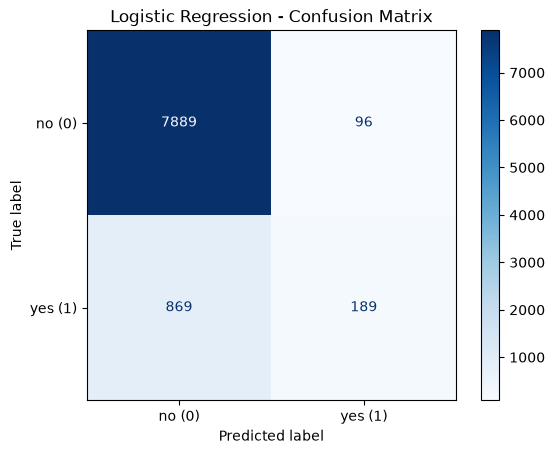

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_encoded, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["no (0)", "yes (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [20]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

threshold = 0.3
y_pred_03 = (y_proba >= threshold).astype(int)

cm_03 = confusion_matrix(y_test_encoded, y_pred_03)

print("Confusion Matrix (threshold = 0.3):")
print(cm_03)

print(f"Precision: {precision_score(y_test_encoded, y_pred_03):.4f}")
print(f"Recall:    {recall_score(y_test_encoded, y_pred_03):.4f}")
print(f"F1-score:  {f1_score(y_test_encoded, y_pred_03):.4f}")

Confusion Matrix (threshold = 0.3):
[[7703  282]
 [ 706  352]]
Precision: 0.5552
Recall:    0.3327
F1-score:  0.4161


In [23]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective = "binary:logistic",
    eval_metric = "logloss",
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 3,
    random_state = 42,
    n_jobs = -1
)

print("XGBoost model created successfully.")

XGBoost model created successfully.


In [24]:
from sklearn.pipeline import Pipeline

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_model)
    ]
)

print("XGBoost pipeline created successfully.")

XGBoost pipeline created successfully.


In [25]:
xgb_pipeline.fit(X_train, y_train_encoded)

print("XGBoost training completed.")

XGBoost training completed.


In [26]:
y_pred_xgb = xgb_pipeline.predict(X_test)

y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("First 10 predictions:", y_pred_xgb[:10])
print("First 10 actual labels:", y_test_encoded.iloc[:10].to_list())
print("First 10 predicted probabilities:", y_proba_xgb[:10])

First 10 predictions: [0 0 0 0 0 0 0 1 0 0]
First 10 actual labels: [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
First 10 predicted probabilities: [0.02638704 0.03296652 0.03077787 0.02856491 0.11902463 0.05452059
 0.05563983 0.75889635 0.09629013 0.08977637]


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy = accuracy_score(y_test_encoded, y_pred_xgb)
precision = precision_score(y_test_encoded, y_pred_xgb)
recall = recall_score(y_test_encoded, y_pred_xgb)
f1 = f1_score(y_test_encoded, y_pred_xgb)
roc_auc = roc_auc_score(y_test_encoded, y_proba_xgb)
pr_auc = average_precision_score(y_test_encoded, y_proba_xgb)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}")

Accuracy : 0.8946
Precision: 0.6721
Recall   : 0.1938
F1-score : 0.3008
ROC-AUC  : 0.8009
PR-AUC   : 0.4571


In [28]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "F1-score", "ROC-AUC", "PR-AUC"
    ],
    "Logistic Regression": [
        0.8933, 0.6632, 0.1786,
        0.2815, 0.7717, 0.4111
    ],
    "XGBoost": [
        0.8946, 0.6721, 0.1938,
        0.3008, 0.8009, 0.4571
    ]
})

comparison_df

,Metric,Logistic Regression,XGBoost
0,Accuracy,0.8933,0.8946
1,Precision,0.6632,0.6721
2,Recall,0.1786,0.1938
3,F1-score,0.2815,0.3008
4,ROC-AUC,0.7717,0.8009
5,PR-AUC,0.4111,0.4571


In [29]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_train_encoded
)

print("X_train_new:", X_train_new.shape)
print("X_val      :", X_val.shape)
print("X_test     :", X_test.shape)

print("\nPositive rate:")
print("Train     :", y_train_new.mean().round(4))
print("Validation:", y_val.mean().round(4))
print("Test      :", y_test_encoded.mean().round(4))

X_train_new: (28934, 15)
X_val      : (7234, 15)
X_test     : (9043, 15)

Positive rate:
Train     : 0.117
Validation: 0.1169
Test      : 0.117


In [30]:
negative_count = (y_train_new == 0).sum()
positive_count = (y_train_new == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print(f"scale_pos_weight: {scale_pos_weight:.4f}")

Negative samples: 25549
Positive samples: 3385
scale_pos_weight: 7.5477


In [31]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_weighted = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

xgb_weighted_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_weighted)
    ]
)

xgb_weighted_pipeline.fit(X_train_new, y_train_new)

print("Weighted XGBoost training completed.")

Weighted XGBoost training completed.


In [32]:
y_val_pred = xgb_weighted_pipeline.predict(X_val)

y_val_proba = xgb_weighted_pipeline.predict_proba(X_val)[:, 1]

print("First 10 predictions:", y_val_pred[:10])
print("First 10 actual labels:", y_val.iloc[:10].to_list())
print("First 10 predicted probabilities:", y_val_proba[:10])

First 10 predictions: [1 0 1 0 0 1 1 1 1 0]
First 10 actual labels: [1, 0, 1, 0, 0, 0, 1, 0, 0, 0]
First 10 predicted probabilities: [0.5251222  0.4640413  0.8950368  0.17038302 0.20344126 0.73162913
 0.7861418  0.51596147 0.57338196 0.16319549]


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy_val = accuracy_score(y_val, y_val_pred)
precision_val = precision_score(y_val, y_val_pred)
recall_val = recall_score(y_val, y_val_pred)
f1_val = f1_score(y_val, y_val_pred)
roc_auc_val = roc_auc_score(y_val, y_val_proba)
pr_auc_val = average_precision_score(y_val, y_val_proba)

print(f"Accuracy : {accuracy_val:.4f}")
print(f"Precision: {precision_val:.4f}")
print(f"Recall   : {recall_val:.4f}")
print(f"F1-score : {f1_val:.4f}")
print(f"ROC-AUC  : {roc_auc_val:.4f}")
print(f"PR-AUC   : {pr_auc_val:.4f}")

Accuracy : 0.8054
Precision: 0.3287
Recall   : 0.6371
F1-score : 0.4336
ROC-AUC  : 0.7993
PR-AUC   : 0.4443


In [34]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_baseline_val = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_baseline_val_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_baseline_val)
    ]
)

xgb_baseline_val_pipeline.fit(X_train_new, y_train_new)

print("Baseline XGBoost training completed.")

Baseline XGBoost training completed.


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

y_val_pred_baseline = xgb_baseline_val_pipeline.predict(X_val)

y_val_proba_baseline = (
    xgb_baseline_val_pipeline.predict_proba(X_val)[:, 1]
)

baseline_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_baseline),
    "Precision": precision_score(y_val, y_val_pred_baseline),
    "Recall": recall_score(y_val, y_val_pred_baseline),
    "F1-score": f1_score(y_val, y_val_pred_baseline),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_baseline),
    "PR-AUC": average_precision_score(y_val, y_val_proba_baseline)
}

for metric, value in baseline_metrics.items():
    print(f"{metric:10}: {value:.4f}")

Accuracy  : 0.8956
Precision : 0.6857
Recall    : 0.1986
F1-score  : 0.3080
ROC-AUC   : 0.8023
PR-AUC    : 0.4561


In [36]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (
        y_val_proba_baseline >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred_threshold),
        "Recall": recall_score(y_val, y_pred_threshold),
        "F1-score": f1_score(y_val, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(4)

,Threshold,Precision,Recall,F1-score
0,0.2,0.4741,0.5296,0.5003
1,0.3,0.5478,0.3995,0.4621
2,0.4,0.6178,0.2790,0.3844
3,0.5,0.6857,0.1986,0.3080


In [37]:
thresholds = np.arange(0.10, 0.301, 0.02)

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (
        y_val_proba_baseline >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred_threshold),
        "Recall": recall_score(y_val, y_pred_threshold),
        "F1-score": f1_score(y_val, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df = threshold_df.sort_values(
    by="F1-score",
    ascending=False
)

threshold_df.round(4)

,Threshold,Precision,Recall,F1-score
5,0.20,0.4741,0.5296,0.5003
6,0.22,0.4902,0.5047,0.4974
4,0.18,0.4512,0.5461,0.4941
3,0.16,0.4268,0.5757,0.4902
7,0.24,0.5019,0.4787,0.4900
8,0.26,0.5184,0.4492,0.4813
2,0.14,0.3831,0.6099,0.4706
9,0.28,0.5312,0.4220,0.4704
10,0.30,0.5478,0.3995,0.4621
1,0.12,0.3286,0.6584,0.4384


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_test_proba_final = (
    xgb_baseline_val_pipeline.predict_proba(X_test)[:, 1]
)

final_threshold = 0.20
y_test_pred_final = (
    y_test_proba_final >= final_threshold
).astype(int)

print(f"Threshold: {final_threshold:.2f}")
print(f"Accuracy : {accuracy_score(y_test_encoded, y_test_pred_final):.4f}")
print(f"Precision: {precision_score(y_test_encoded, y_test_pred_final):.4f}")
print(f"Recall   : {recall_score(y_test_encoded, y_test_pred_final):.4f}")
print(f"F1-score : {f1_score(y_test_encoded, y_test_pred_final):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_encoded, y_test_proba_final):.4f}")
print(f"PR-AUC   : {average_precision_score(y_test_encoded, y_test_proba_final):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_encoded, y_test_pred_final))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_test_pred_final,
    target_names=["no", "yes"]
))

Threshold: 0.20
Accuracy : 0.8784
Precision: 0.4810
Recall   : 0.5019
F1-score : 0.4912
ROC-AUC  : 0.8010
PR-AUC   : 0.4494

Confusion Matrix:
[[7412  573]
 [ 527  531]]

Classification Report:
              precision    recall  f1-score   support

          no       0.93      0.93      0.93      7985
         yes       0.48      0.50      0.49      1058

    accuracy                           0.88      9043
   macro avg       0.71      0.72      0.71      9043
weighted avg       0.88      0.88      0.88      9043



In [39]:
final_results = pd.DataFrame([
    {
        "Model": "Baseline XGBoost",
        "Threshold": 0.20,
        "Accuracy": accuracy_score(y_test_encoded, y_test_pred_final),
        "Precision": precision_score(y_test_encoded, y_test_pred_final),
        "Recall": recall_score(y_test_encoded, y_test_pred_final),
        "F1-score": f1_score(y_test_encoded, y_test_pred_final),
        "ROC-AUC": roc_auc_score(
            y_test_encoded, y_test_proba_final
        ),
        "PR-AUC": average_precision_score(
            y_test_encoded, y_test_proba_final
        )
    }
])

final_results.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Baseline XGBoost,0.2,0.8784,0.481,0.5019,0.4912,0.801,0.4494


THỬ NGHIỆM CÁC THAM SỐ KHÁC NHAU CỦA MÔ HÌNH

In [40]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

xgb_tuned = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_tuned_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_tuned)
    ]
)

xgb_tuned_pipeline.fit(X_train_new, y_train_new)

y_val_proba_tuned = (
    xgb_tuned_pipeline.predict_proba(X_val)[:, 1]
)

threshold = 0.20
y_val_pred_tuned = (
    y_val_proba_tuned >= threshold
).astype(int)

print(f"Precision: {precision_score(y_val, y_val_pred_tuned):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred_tuned):.4f}")
print(f"F1-score : {f1_score(y_val, y_val_pred_tuned):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, y_val_proba_tuned):.4f}")
print(f"PR-AUC   : {average_precision_score(y_val, y_val_proba_tuned):.4f}")

Precision: 0.4653
Recall   : 0.5544
F1-score : 0.5059
ROC-AUC  : 0.8088
PR-AUC   : 0.4716


In [41]:
xgb_tuned_2 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_tuned_2_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_tuned_2)
    ]
)

xgb_tuned_2_pipeline.fit(X_train_new, y_train_new)

y_val_proba_tuned_2 = (
    xgb_tuned_2_pipeline.predict_proba(X_val)[:, 1]
)

y_val_pred_tuned_2 = (
    y_val_proba_tuned_2 >= 0.20
).astype(int)

print(f"Precision: {precision_score(y_val, y_val_pred_tuned_2):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred_tuned_2):.4f}")
print(f"F1-score : {f1_score(y_val, y_val_pred_tuned_2):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, y_val_proba_tuned_2):.4f}")
print(f"PR-AUC   : {average_precision_score(y_val, y_val_proba_tuned_2):.4f}")

Precision: 0.4697
Recall   : 0.5402
F1-score : 0.5025
ROC-AUC  : 0.8068
PR-AUC   : 0.4660


In [42]:
xgb_tuned_3 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    random_state=42,
    n_jobs=-1
)

xgb_tuned_3_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_tuned_3)
    ]
)

xgb_tuned_3_pipeline.fit(X_train_new, y_train_new)

y_val_proba_tuned_3 = (
    xgb_tuned_3_pipeline.predict_proba(X_val)[:, 1]
)

y_val_pred_tuned_3 = (
    y_val_proba_tuned_3 >= 0.20
).astype(int)

print(f"Precision: {precision_score(y_val, y_val_pred_tuned_3):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred_tuned_3):.4f}")
print(f"F1-score : {f1_score(y_val, y_val_pred_tuned_3):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, y_val_proba_tuned_3):.4f}")
print(f"PR-AUC   : {average_precision_score(y_val, y_val_proba_tuned_3):.4f}")

Precision: 0.4639
Recall   : 0.5544
F1-score : 0.5051
ROC-AUC  : 0.8087
PR-AUC   : 0.4709


In [43]:
xgb_tuned_4 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_tuned_4_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_tuned_4)
    ]
)

xgb_tuned_4_pipeline.fit(X_train_new, y_train_new)

y_val_proba_tuned_4 = (
    xgb_tuned_4_pipeline.predict_proba(X_val)[:, 1]
)

y_val_pred_tuned_4 = (
    y_val_proba_tuned_4 >= 0.20
).astype(int)

print(f"Precision: {precision_score(y_val, y_val_pred_tuned_4):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred_tuned_4):.4f}")
print(f"F1-score : {f1_score(y_val, y_val_pred_tuned_4):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, y_val_proba_tuned_4):.4f}")
print(f"PR-AUC   : {average_precision_score(y_val, y_val_proba_tuned_4):.4f}")

Precision: 0.4656
Recall   : 0.5591
F1-score : 0.5081
ROC-AUC  : 0.8083
PR-AUC   : 0.4740


In [45]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

cv_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    cv_pipeline,
    X_train_new,
    y_train_new,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision"
    },
    n_jobs=1,
    return_train_score=False
)

print(f"ROC-AUC: {np.mean(cv_results['test_roc_auc']):.4f} "
      f"+/- {np.std(cv_results['test_roc_auc']):.4f}")

print(f"PR-AUC : {np.mean(cv_results['test_pr_auc']):.4f} "
      f"+/- {np.std(cv_results['test_pr_auc']):.4f}")

ROC-AUC: 0.7977 +/- 0.0089
PR-AUC : 0.4422 +/- 0.0287


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

baseline_cv_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

baseline_cv_results = cross_validate(
    baseline_cv_pipeline,
    X_train_new,
    y_train_new,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print(
    f"Baseline ROC-AUC: "
    f"{baseline_cv_results['test_roc_auc'].mean():.4f} "
    f"+/- {baseline_cv_results['test_roc_auc'].std():.4f}"
)

print(
    f"Baseline PR-AUC : "
    f"{baseline_cv_results['test_pr_auc'].mean():.4f} "
    f"+/- {baseline_cv_results['test_pr_auc'].std():.4f}"
)

Baseline ROC-AUC: 0.7904 +/- 0.0104
Baseline PR-AUC : 0.4313 +/- 0.0289


In [47]:
cv_comparison = pd.DataFrame([
    {
        "Model": "Baseline XGBoost",
        "ROC-AUC mean": baseline_cv_results["test_roc_auc"].mean(),
        "ROC-AUC std": baseline_cv_results["test_roc_auc"].std(),
        "PR-AUC mean": baseline_cv_results["test_pr_auc"].mean(),
        "PR-AUC std": baseline_cv_results["test_pr_auc"].std(),
    },
    {
        "Model": "Tuned XGBoost",
        "ROC-AUC mean": cv_results["test_roc_auc"].mean(),
        "ROC-AUC std": cv_results["test_roc_auc"].std(),
        "PR-AUC mean": cv_results["test_pr_auc"].mean(),
        "PR-AUC std": cv_results["test_pr_auc"].std(),
    }
])

cv_comparison.round(4)

,Model,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std
0,Baseline XGBoost,0.7904,0.0104,0.4313,0.0289
1,Tuned XGBoost,0.7977,0.0089,0.4422,0.0287


In [ ]:

from src.preprocessor import DataPreprocessor
from src.model_trainer import ModelTrainer

categorical_columns = X_train_new.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_columns = X_train_new.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))


Categorical columns: 9
Numerical columns: 6


In [49]:

preprocessor = DataPreprocessor(
    categorical_columns=categorical_columns,
    numerical_columns=numerical_columns,
)

trainer = ModelTrainer(
    preprocessor=preprocessor,
    model_params={
        "n_estimators": 300,
        "learning_rate": 0.05,
        "max_depth": 4,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
    },
)

trainer.fit(X_train_new, y_train_new)

print("Training completed!")


Training completed!


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

y_val_proba = trainer.predict_proba(X_val)

threshold = 0.20
y_val_pred = (y_val_proba >= threshold).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred, zero_division=0),
    "F1-score": f1_score(y_val, y_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba),
    "PR-AUC": average_precision_score(y_val, y_val_proba),
}

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred))


Accuracy: 0.8734
Precision: 0.4656
Recall: 0.5591
F1-score: 0.5081
ROC-AUC: 0.8083
PR-AUC: 0.4740

Confusion matrix:
[[5845  543]
 [ 373  473]]


In [51]:

from src.model_evaluator import ModelEvaluator

evaluator = ModelEvaluator(threshold=0.20)

y_val_proba = trainer.predict_proba(X_val)
metrics = evaluator.evaluate(y_val, y_val_proba)

for name, value in metrics.items():
    print(f"{name.replace('_', '-').upper()}: {value:.4f}")

print("\nConfusion matrix:")
print(evaluator.get_confusion_matrix())


ACCURACY: 0.8734
PRECISION: 0.4656
RECALL: 0.5591
F1: 0.5081
ROC-AUC: 0.8083
PR-AUC: 0.4740

Confusion matrix:
[[5845  543]
 [ 373  473]]
